# A detailed analysis of one balloon segment

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

from matplotlib.dates import DateFormatter

### Constants

In [41]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 2.0 # (minutes) the time step of the interpolated data

# Set the GW period range
GW_PERIOD_MIN = 10     # (minutes) the minimum period for GW packets is the maximum of this and the buoyancy period
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum period for GW packets is the minimum of this and the Coriolis period

# Parameters for identifying and quantifying maxima in the total momentum flux wavelet
STENCIL_DIM = 3 # (must be an odd number) the size of the stencil for averaging quantities near the momentum flux
                # maximum. The stencil has a size STENCIL_DIM x STENCIL_DIM wavelet coefficients, centered on the maximum
FLUX_THRESHOLD = 50 # (mPa) the threshold of the frequency-integrated total momentum flux to look identify times
                    # to look for maxima

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98
synchrosqueeze = 0

### Load in the processed Loon data

The data are interpolated to have a constant time step of 2 minutes.

In [4]:
flights = pd.read_feather('5_flights_interptime_2daysegments_new_commontime.feather')

# Select just the flights that start in 2014
flight_time_start = flights.groupby('flight_id').apply(lambda f: f.time.iloc[0])
flight_ids = flight_time_start[flight_time_start < pd.Timestamp('2015-01-01 00:00:00')]
flight_ids = flight_ids[flight_ids >= pd.Timestamp('2014-01-01 00:00:00')]
flights = flights[flights.flight_id.isin(flight_ids.index)]

# Select segments that fly inside a lat/lon box
# Andes:
lat_box_min = -55
lat_box_max = -30
lon_box_min = -80
lon_box_max = -60
flights[['in_box1','in_box2','in_box3','in_box4']] = 0
flights.loc[flights.latitude >= lat_box_min, 'in_box1'] = 1
flights.loc[flights.latitude <= lat_box_max, 'in_box2'] = 1
flights.loc[flights.longitude >= lon_box_min, 'in_box3'] = 1
flights.loc[flights.longitude <= lon_box_max, 'in_box4'] = 1
flights['in_box'] = flights.in_box1 + flights.in_box2 + flights.in_box3 + flights.in_box4
segments_to_select = flights[flights.in_box == 4].segment_id.unique()
flights = flights[flights.segment_id.isin(segments_to_select)]
flights = flights.drop(columns=['in_box1','in_box2','in_box3','in_box4','in_box'])

print('Number of candidate segments:', flights.segment_id.nunique())
print('')
print('Segment IDs:', flights.segment_id.unique())
print('')
print('Flight IDs:', flights.flight_id.unique())

Number of candidate segments: 145

Segment IDs: [ 103  105  106  107  108  109  110  111  112  113  134  140  146  151
  152  164  515  537  543  557  573  691  815  829  852  896  903  930
  938 1068 1079 1099 1127 1156 1224 1313 1319 1479 1513 1515 1529 1550
 1566 1570 1585 1591 1595 1600 1606 1623 1627 1629 1782 2017 2062 2103
 2170 2213 2248 2257 2283 2382 2466 2559 2583 2682 2690 2751 2771 2915
 2916 2924 2962 2969 2972 3004 3021 3025 3029 3030 3077 3136 3150 3159
 3163 3249 3251 3283 3333 3352 3355 3395 3458 3473 3488 3578 3583 3717
 3746 3770 3864 3996 3999 4000 4082 4128 4142 4181 4187 4266 4274 4313
 4315 4331 4370 4444 4507 4565 4651 4652 4890 4951 4956 5039 5048 5077
 5164 5166 5209 5210 5234 5273 5280 5328 5330 5331 5343 5411 5569 5606
 5645 5648 5691 5706 5719]

Flight IDs: ['I-152' 'I-153' 'I-154' 'I-155' 'I-156' 'I-157' 'I-158' 'I-159' 'I-160'
 'I-161' 'I-162' 'I-164' 'I-166' 'I-167' 'I-208' 'I-209' 'I-210' 'I-221'
 'I-226' 'I-227' 'I-230' 'I-231' 'I-232' 'I-234' 'I-237'

In [6]:
temp = flights[flights.flight_id == 'I-162']
temp.segment_id.unique()

array([134])

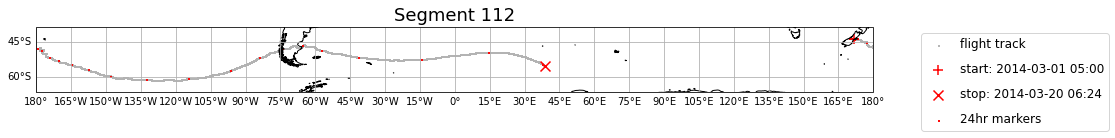

In [7]:
# Select one segment
segment_ids = flights.segment_id.unique()
#segment = flights[flights.segment_id == segment_ids[0]]
segment = flights[flights.segment_id == 112] # segment 112 (flight I-160) is the segment in the paper
# candidates: 1627, 152, 140, 134, 113, 112, 111, 109
# fine: 1627, 152, 134, 113, 111, 109
# better: 140, 112

# North Africa segments:
#segment = flights[flights.segment_id == 7115]
#segment = flights[flights.segment_id == 7493]
#segment = flights[flights.segment_id == 7595]
#segment = flights[flights.segment_id == 7597]
#segment = flights[flights.segment_id == 7687]
#segment = flights[flights.segment_id == 8703] # this one is important for the time mean zonal flux
#segment = flights[flights.segment_id == 8879] # big GW at the end
#segment = flights[flights.segment_id == 9220]
#segment = flights[flights.segment_id == 9667]
#segment = flights[flights.segment_id == 9815] # enormous negative (-600 mPa) zonal momentum flux
#segment = flights[flights.segment_id == 9817] # a couple of > 100 mPa momentum fluxes
#segment = flights[flights.segment_id == 17612]

## Plot the segment
## Old method, using Basemap:
#fig = plt.figure(num=None, figsize=(20,20))
#lat = np.array(segment.latitude.copy())
#lon = np.array(segment.longitude.copy())
#m = Basemap(llcrnrlon=np.max([-180, np.min(lon)-5]),
#            llcrnrlat=np.max([-90, np.min(lat)-5]),
#            urcrnrlon=np.min([180, np.max(lon)+5]),
#            urcrnrlat=np.min([90, np.max(lat)+5]),
#            resolution='l',projection='cyl')
#m.drawcoastlines()
##m.drawparallels(np.arange(-90.,91.,5),labels=[1,0,0,0],fontsize=14)
##m.drawmeridians(np.arange(-180.,181.,5),labels=[0,0,0,1],fontsize=14)
#m.drawparallels(np.arange(-90.,91.,15),labels=[1,0,0,0],fontsize=14)
#m.drawmeridians(np.arange(-180.,181.,30),labels=[0,0,0,1],fontsize=14)
#x, y = m(np.array(lon), np.array(lat))
#plots = np.ndarray(shape=4,dtype='object')
#plots[0] = m.scatter(x, y, s=1, marker='s', color=[0.7,0.7,0.7])
#plots[1] = m.scatter(x[0], y[0], s=100, marker='+', color='r')
#plots[2] = m.scatter(x[-1], y[-1], s=100, marker='x', color='r')
##plots[3] = m.scatter(x[0:-1:180], y[0:-1:180], s=1, marker='s', color='r')
#plots[3] = m.scatter(x[0:-1:4*180], y[0:-1:4*180], s=1, marker='s', color='r')
#plt.title('Segment '+str(segment.segment_id.iloc[0]), fontsize=18)
#labels = np.ndarray(shape=4,dtype='object')
#labels[0] = 'flight track'
#labels[1] = 'start: '+str(segment.time.iloc[0].floor('min'))[:-3]
#labels[2] = 'stop: '+str(segment.time.iloc[-1].floor('min'))[:-3]
#labels[3] = '24hr markers'
#leg = plt.legend(plots, labels, fontsize=12, bbox_to_anchor=(1.05, 1),
#                     loc='upper left', labelspacing=1);
##fig.savefig('plots/temp1.png', format='png', bbox_inches='tight');

# Plot the segment
# New method, using Cartopy:
plt.figure(figsize=(15,15))
lat = np.array(segment.latitude.copy())
lon = np.array(segment.longitude.copy())
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([np.max([-180, np.min(lon)-5]), 
               np.min([180, np.max(lon)+5]), 
               np.max([-90, np.min(lat)-5]),
               np.min([90, np.max(lat)+5])], crs=ccrs.PlateCarree())
ax.coastlines(resolution='50m') # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,15))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,15))
plots = np.ndarray(shape=4,dtype='object')
plots[0] = plt.scatter(lon, lat, s=1, marker='s', color=[0.7,0.7,0.7], transform=ccrs.PlateCarree())
plots[1] = plt.scatter(lon[0], lat[0], s=100, marker='+', color='r', transform=ccrs.PlateCarree())
plots[2] = plt.scatter(lon[-1], lat[-1], s=100, marker='x', color='r', transform=ccrs.PlateCarree())
plots[3] = plt.scatter(lon[0:-1:4*180], lat[0:-1:4*180], s=1, marker='s', color='r', transform=ccrs.PlateCarree())
plt.title('Segment '+str(segment.segment_id.iloc[0]), fontsize=18)
labels = np.ndarray(shape=4,dtype='object')
labels[0] = 'flight track'
labels[1] = 'start: '+str(segment.time.iloc[0].floor('min'))[:-3]
labels[2] = 'stop: '+str(segment.time.iloc[-1].floor('min'))[:-3]
labels[3] = '24hr markers'
leg = plt.legend(plots, labels, fontsize=12, bbox_to_anchor=(1.05, 1),
                     loc='upper left', labelspacing=1);
#plt.savefig('../plots/temp1.png', format='png', bbox_inches='tight');

### Wavelet analysis function

In [40]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    X_recon: float;
    wave: float;
    wave_power: float;
    total_power: float;
    global_power: float;
    global_power_rescaling: float;
    total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    fftfreq: float;
    fft: float;
    fft_power: float;
    fft_total_power: float;
    fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj,synchrosqueeze):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
        
    # Synchrosqueeze
    if synchrosqueeze == 1:
        
        # Calculate the instantaneous frequency, according to Daubechies et al. (2011) Eq. 2.3
        omegaS = np.nan*(1+1j)*np.ones(shape=(nscales,N+2))
        omegaS[:,1:-1] = wave.copy()
        omegaS[:,0] = wave[:,-1]
        omegaS[:,-1] = wave[:,0]
        omegaS = 0.5*(omegaS[:,2:] - omegaS[:,:-2])/dt
        # errors in d(wave)/dt mean that -1j*omegaS/wave isn't purely real:
        omegaS = np.abs(-1j*omegaS/wave)/(2*np.pi) 
        
        # Determine the frequency bins and the remapping
        # Since the wavelet scales are evenly spaced in log of frequency, figure out how
        # much shifting of the scale index by taking the difference of logfreqI and log(frequency)
        dlogfrequency = dj*np.log(2)
        logfrequency = np.tile(np.log(frequency),(N,1)).swapaxes(0,1)
        ind_new = np.round((logfrequency - np.log(omegaS))/dlogfrequency, decimals=0)
        del logfrequency, omegaS
        ind_new = ind_new + np.tile(np.arange(nscales),(N,1)).swapaxes(0,1)
        
        # Normalize the wavelet transform by the square root of the wavelet scale
        wave = wave/np.sqrt(s_tiled)
        
        # Reassign the wavelet coefficients to their instantaneous frequencies and
        # reverse the normalization
        wave_new = np.nan*(1+1j)*np.ones(shape=(nscales,N))
        for i in np.arange(nscales):
            temp = wave.copy()
            temp[ind_new != i] = 0
            wave_new[i,:] = np.nansum(temp, axis=0)
        del temp
        wave = np.sqrt(s_tiled)*wave_new
        del wave_new
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    # Reconstruct the input time series
    psi_0_0 = np.pi**-0.25 # (Table 2)
    X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    # The scaling is chosen so that the values are correct after the zero padding is removed
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    wave_power = (var/var_ratio)*np.abs(wave)**2
    global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    global_total_power = (1/N)*np.sum(total_power)
    X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    # FFT analysis
    ind_switchfreq_fft = 1 + int(np.floor(N/2))
    fft = np.fft.fft(X/std)
    fftfreq = np.fft.fftfreq(N,dt)
    fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    fft_total_power = (1/N)*np.sum(fft_power)
    fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       X_recon,
                       wave,
                       wave_power,
                       total_power,
                       global_power,
                       global_power_rescaling,
                       total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi,
                       fftfreq,
                       fft,
                       fft_power,
                       fft_total_power,
                       fft_power_rescaling)

### Prepare the segment for analysis

rho_bar: 0.08311816096857409
H: 6380.976298029224
Nref: 0.021385854283771072
Z_EDS: 0.2939764483383555


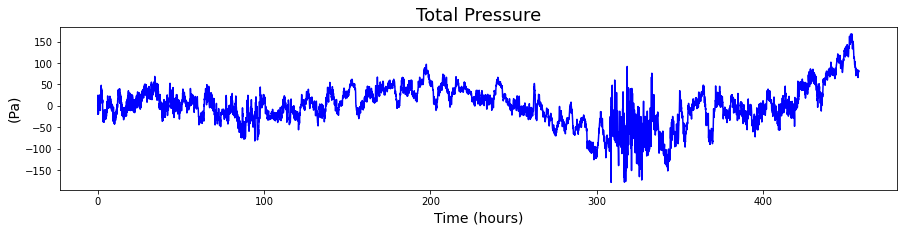

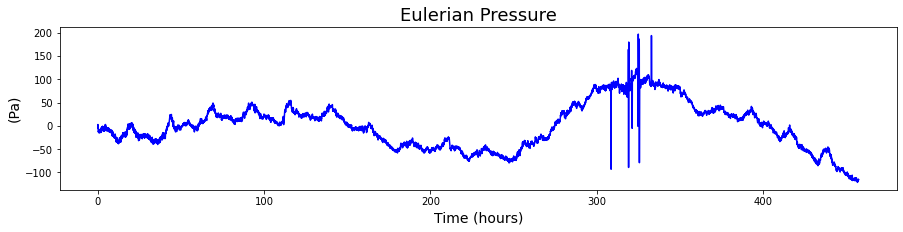

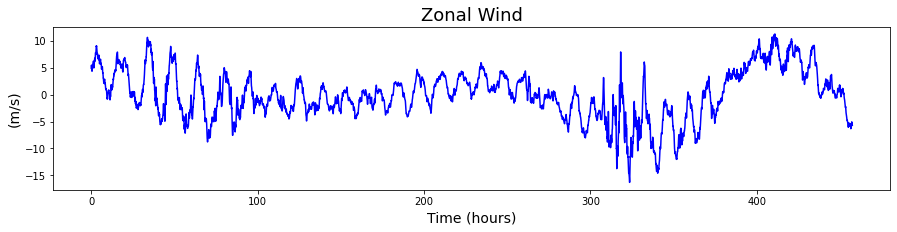

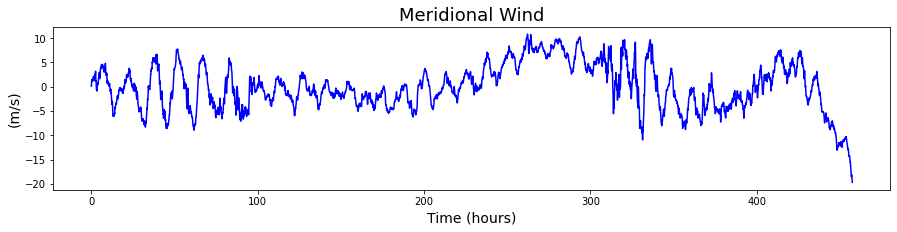

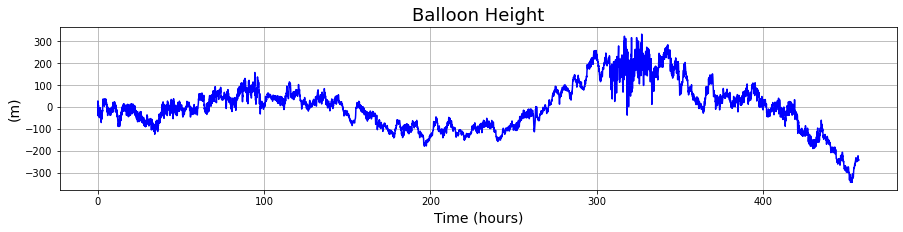

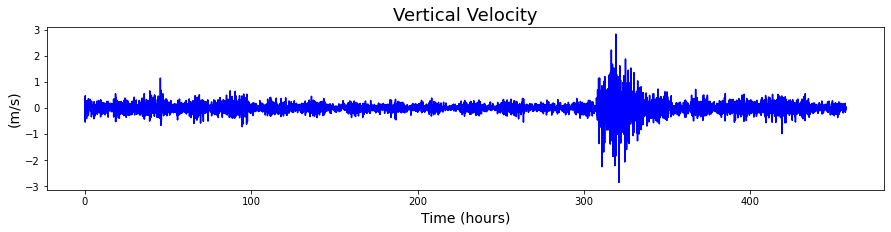

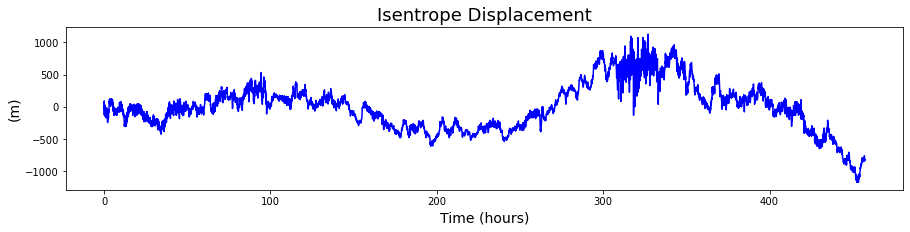

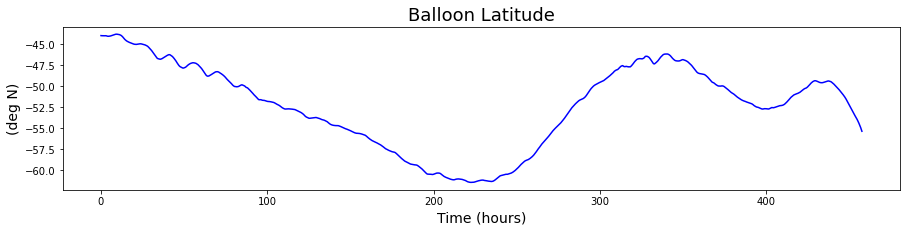

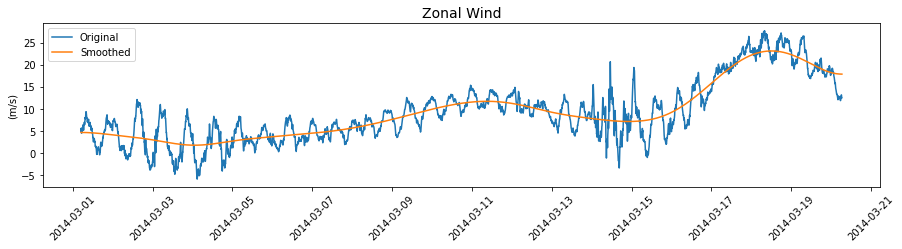

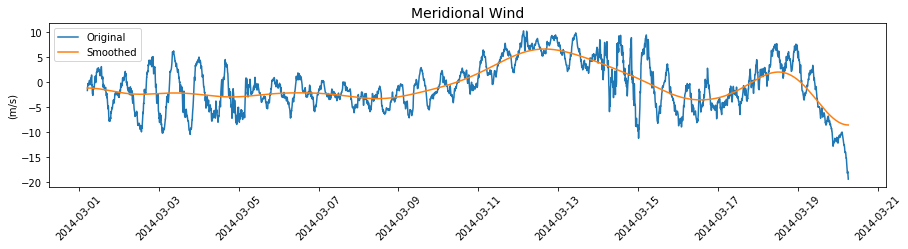

In [8]:
# Convert time to a numpy array with units of minutes
t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
N = np.size(t)
# Make other variables arrays
u = np.array(segment.wind_u)
v = np.array(segment.wind_v)
pt = 100*np.array(segment.pressure) # the Zenodo data has pressure units of hPa; convert to Pa
altitude = np.array(segment.altitude)
balloon_lat = np.array(segment.latitude)
balloon_lon = np.array(segment.longitude)
T_env = np.array(segment.T_cosmic) + 273.15 # COSMIC temperatures are in degrees Celsius; convert to Kelvin
dTdz_env = np.array(segment.dTdz_cosmic)

# When N_cosmic = 0, set T_env and dTdz_env to np.nan
# Later, when flight-mean rho_bar, H, Nref, and Z_EDS are calculated, use np.nanmean
N_cosmic = np.array(segment.N_cosmic)
T_env[N_cosmic == 0] = np.nan
dTdz_env[N_cosmic == 0] = np.nan
    
# Calculate segment mean density. Because Loon temperature data is unreliable, use the
# environmental temperature from the COSMIC profiles
rho_bar = np.nanmean(pt/(R*T_env))

# Calculate the segment mean density scale height (CHECK THAT RT/g IS THE APPROPRIATE FORMULATION)
H = np.nanmean(R*T_env/g)

# Calculate the segment mean Coriolis parameter
f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180))
    
# Calculate the time series of the environmental buoyancy frequency and Z_EDS
Nref = np.sqrt((g/T_env)*((g/cp) + dTdz_env)) # VH14 Eq. 6
Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
# As a start, to keep things simple, average them in time
Nref = np.nanmean(Nref)
Z_EDS = np.nanmean(Z_EDS)
print('rho_bar:', rho_bar)
print('H:', H)
print('Nref:', Nref)
print('Z_EDS:', Z_EDS)
    
# Calculate "smooth" velocities by using a Gaussian filter. The width (standard deviation) of the filter
# is determined by the longest period GW: either the Coriolis period or GW_PERIOD_MAX.
width = 2*Omega*np.sin(np.pi*np.max(np.abs(balloon_lat))/180) # Coriolis frequency, in 1/seconds
width = width/(2*np.pi) # convert from angular frequency to cyclic frequency
width = 1/(60*width) # period, in minutes
width = min(width, GW_PERIOD_MAX)/dt
u_smooth = gaussian_filter(u, sigma=width)
v_smooth = gaussian_filter(v, sigma=width)
    
# Create time series of anomalies by detrending
u = scipy.signal.detrend(u)
v = scipy.signal.detrend(v)
pt = scipy.signal.detrend(pt)
delta_b = scipy.signal.detrend(altitude)

# Back out the Eulerian pressure perturbation
p = pt + rho_bar*g*delta_b # VH14 Eq. 21
    
# Calculate delta_theta and w, using Z_EDS
delta_theta = delta_b/Z_EDS
w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt) # make sure dt is in seconds, not minutes
    
# Calculate the mean EKE and potential energy
Ekh = 0.5*np.mean(u**2 + v**2)
Ekv = 0.5*np.mean(w**2)
Ep = 0.5*(Nref**2)*np.mean(delta_theta**2) # Eq. 2, Podglajen et al 2016

## PLOTS
plt.figure(figsize=(15,3))
plt.plot(t/60,pt,'b')
plt.title('Total Pressure', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(Pa)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,p,'b')
plt.title('Eulerian Pressure', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(Pa)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,u,'b')
plt.title('Zonal Wind', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(15,3))
plt.plot(t/60,v,'b')
plt.title('Meridional Wind', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,delta_b,'b')
plt.grid()
plt.title('Balloon Height', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m)', fontsize=14);
#plt.savefig('../plots/2014_segments/segment2498_delta_b.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(15,3))
plt.plot(t/60,w,'b')
plt.title('Vertical Velocity', fontsize=18)
#plt.ylim(-10, 10)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,delta_theta,'b')
plt.title('Isentrope Displacement', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,balloon_lat,'b')
plt.title('Balloon Latitude', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(deg N)', fontsize=14);

plt.figure(figsize = (15,3))
plt.plot(segment.time, segment.wind_u)
plt.plot(segment.time, u_smooth)
plt.xticks(rotation = 45)
plt.title('Zonal Wind',fontsize=14)
plt.ylabel('(m/s)')
plt.legend(['Original','Smoothed']);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize = (15,3))
plt.plot(segment.time, segment.wind_v)
plt.plot(segment.time, v_smooth)
plt.xticks(rotation = 45)
plt.title('Meridional Wind',fontsize=14)
plt.ylabel('(m/s)')
plt.legend(['Original','Smoothed']);

### Run the wavelet analysis

In [42]:
N = np.size(t)

# Normalize the time series
std_w = np.std(w)
std_u = np.std(u)
std_v = np.std(v)
std_delta_theta = np.std(delta_theta)
std_delta_b = np.std(delta_b)
std_p = np.std(p)
std_pt = np.std(pt)
var_w = std_w**2
var_u = std_u**2
var_v = std_v**2
var_delta_theta = std_delta_theta**2
var_delta_b = std_delta_b**2
var_p = std_p**2
var_pt = std_pt**2

# Run the wavelet analysis
print('w')
w_output = run_Morlet_CWT(w,dt,omega0,dj,synchrosqueeze)
print('u')
u_output = run_Morlet_CWT(u,dt,omega0,dj,synchrosqueeze)
print('v')
v_output = run_Morlet_CWT(v,dt,omega0,dj,synchrosqueeze)
print('delta_theta')
delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj,synchrosqueeze)

# Pull out a couple common variables to make some calculations easier
period = u_output.period; frequency = u_output.frequency; scale = u_output.s
N_pad = u_output.N_pad; fftfreq = u_output.fftfreq; coi = u_output.coi
C_delta = 0.5*(u_output.C_delta + v_output.C_delta)
nscales = np.size(scale)
var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
scale_tiled_padded = np.tile(scale,(N + 2*N_pad,1)).swapaxes(0,1)
period_tiled_padded = np.tile(period,(N + 2*N_pad,1)).swapaxes(0,1)

# Calculate the kinetic energies from the zero-padded wavelet output
wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                            var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
wave_Ekv = (0.5/var_ratio)*var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2
global_Ekh = (1/N)*np.sum(wave_Ekh, axis=1)
global_Ekv = (1/N)*np.sum(wave_Ekv, axis=1)
wave_Ekh_total = dj*np.log(2)*np.sum(global_Ekh*frequency)
wave_Ekv_total = dj*np.log(2)*np.sum(global_Ekv*frequency)
# Do a FFT analysis, for comparison
fft_Ekh = 0.5*(u_output.fft_power_rescaling*u_output.fft_power + 
               v_output.fft_power_rescaling*v_output.fft_power)
fft_Ekv = 0.5*w_output.fft_power_rescaling*w_output.fft_power
fft_Ekh_total = (1/(N*dt))*np.sum(fft_Ekh)
fft_Ekv_total = (1/(N*dt))*np.sum(fft_Ekv)

# Calculate the potential energy from the zero-padded wavelet output
wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
          np.abs(delta_theta_output.wave)**2
global_Ep = (1/N)*np.sum(wave_Ep, axis=1)
wave_Ep_total = dj*np.log(2)*np.sum(global_Ep*frequency)
# Do a FFT analysis, for comparison
fft_Ep = 0.5*(Nref**2)*delta_theta_output.fft_power_rescaling*delta_theta_output.fft_power
fft_Ep_total = (1/(N*dt))*np.sum(fft_Ep)



# Check that the total variance is conserved
print('Variances:   time series           wavelet              numpy fft')
print(f'Vert. vel.:  {var_w},   {w_output.total_global_power},   {w_output.fft_total_power}')
print(f'Zonal wind:  {var_u},   {u_output.total_global_power},   {u_output.fft_total_power}')
print(f'Merid. wind: {var_v},   {v_output.total_global_power},   {v_output.fft_total_power}')
print(f'Eddy horizontal K.E.:   {Ekh},   {wave_Ekh_total},   {fft_Ekh_total}')
print(f'Eddy vertical K.E.:     {Ekv},   {wave_Ekv_total},   {fft_Ekv_total}')
print(f'Eddy P.E.:              {Ep},    {wave_Ep_total},    {fft_Ep_total}')

w
u
v
delta_theta
Variances:   time series           wavelet              numpy fft
Vert. vel.:  0.03794242422155757,   0.037942424221557476,   0.0379426724439081
Zonal wind:  20.087117272900727,   20.08711727290073,   20.08711727290073
Merid. wind: 22.18630032228399,   22.186300322283998,   22.186300322283994
Eddy horizontal K.E.:   21.136708797592362,   21.136708797592362,   21.13670879759236
Eddy vertical K.E.:     0.018971336221954054,   0.018971212110778738,   0.01897133622195405
Eddy P.E.:              31.401957732505547,    31.401957732505544,    31.401957732505533


### Calculate u-w and v-w wavelet cross-spectra and the horizontal angle

In [43]:
# Calculate the cross-spectra of u, v and the vertical velocity
crossspec_u_w = w_output.wave*np.conj(u_output.wave) # this is the normalized spectrum
crossspec_v_w = w_output.wave*np.conj(v_output.wave) # this is the normalized spectrum

# Calculate C_delta so that the cross-spectral power is conserved, using the full
# u-w and v-w cross-spectra
uw_bar = np.nanmean(u*w)
vw_bar = np.nanmean(v*w)
temp = (std_u*std_w/var_ratio)*(dj*dt)* \
        np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
C_delta_uw = (1/N)*np.sum(temp)/uw_bar
temp = (std_v*std_w/var_ratio)*(dj*dt)* \
        np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)
C_delta_vw = (1/N)*np.sum(temp)/vw_bar
cross_total_power_u_w = (std_u*std_w/var_ratio)*(dj*dt/C_delta_uw)* \
                         np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
cross_total_power_v_w = (std_v*std_w/var_ratio)*(dj*dt/C_delta_vw)* \
                         np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)

# Calculate the fft momentum flux
crossspec_u_w_fft = (2*std_u*std_w/N)*w_output.fft*np.conj(u_output.fft)
crossspec_v_w_fft = (2*std_v*std_w/N)*w_output.fft*np.conj(v_output.fft)
crossspec_total_power_u_w_fft = (1/N)*np.sum(np.real(crossspec_u_w_fft))
crossspec_total_power_v_w_fft = (1/N)*np.sum(np.real(crossspec_v_w_fft))

# Print some 1-D statistics for validation
print('uw, vw C_delta:', C_delta_uw, C_delta_vw)
print('u, v, w, delta_theta C_delta:',
      u_output.C_delta, v_output.C_delta,w_output.C_delta, delta_theta_output.C_delta)
print('')
print('u, w covariance (m**2/s**2):')
print('from wavelets; mean(u*w); FFT')
print((1/N)*cross_total_power_u_w.sum(),np.mean(u*w),crossspec_total_power_u_w_fft)
print('')
print('v, w covariance (m**2/s**2):')
print('GWs, from wavelets; all motions, from wavelets; mean(v*w); FFT')
print((1/N)*cross_total_power_v_w.sum(),np.mean(v*w),crossspec_total_power_v_w_fft)
print('')

uw, vw C_delta: 0.5713071271952184 0.5743976127585178
u, v, w, delta_theta C_delta: 0.5656925503659028 0.5650283338648224 0.5707151156358903 0.5678130620298389

u, w covariance (m**2/s**2):
from wavelets; mean(u*w); FFT
-0.024909101433944918 -0.024909101433944914 -0.024909101433944904

v, w covariance (m**2/s**2):
GWs, from wavelets; all motions, from wavelets; mean(v*w); FFT
0.01110422811197114 0.01110422811197114 0.011104228111971141



### Calculate the total momentum flux wavelet

In [44]:
# Re-scale the total energy
wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
# Calculate the scaling factor
balloon_lat_padded = np.nan*np.ones(N+2*N_pad)
balloon_lat_padded[N_pad:N+N_pad] = balloon_lat
balloon_lat_padded[:N_pad] = balloon_lat[0]
balloon_lat_padded[N+N_pad:] = balloon_lat[-1]
f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat_padded/180),(nscales,1))
frequency_rad = 2*np.pi*frequency/60
frequency_rad = np.tile(frequency_rad,(N + 2*N_pad,1)).swapaxes(0,1)
factor = (frequency_rad**2 - f_temp**2)/(Nref**2 - f_temp**2)
factor = factor*(Nref**2 - frequency_rad**2)/(Nref**2 - f_temp**2)
factor = rho_bar*np.sqrt(factor)
del f_temp, frequency_rad
# Do the scaling
wave_Etotal_scaled = factor*wave_Etotal

# Re-scale the u-w and v-w wavelet cross spectra and calculate the total momentum flux
temp = rho_bar*(std_w/var_ratio)*(dt)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
rescaled_ReUVW_total = temp*np.sqrt(np.real(std_u*crossspec_u_w/C_delta_uw)**2 + np.real(std_v*crossspec_v_w/C_delta_uw)**2)
global_ReUVW = (1/N)*np.sum(rescaled_ReUVW_total, axis=1)

# Identify wavelet coefficients with periods higher than GW_PERIOD_MAX
coeff_factor = 60*2*Omega*np.sin(np.pi*np.abs(balloon_lat_padded)/180) # Coriolis frequency in rad/min
coeff_factor = 2*np.pi/coeff_factor # period in minutes
coeff_factor = np.minimum(coeff_factor,GW_PERIOD_MAX)
coeff_factor = np.tile(coeff_factor,(nscales,1))
coeff_factor[coeff_factor < period_tiled_padded] = np.nan
# Identify wavelet coefficients with periods lower than GW_PERIOD_MIN
period_N = 2*np.pi/(60*Nref) # the buoyancy period
min_period = np.maximum(GW_PERIOD_MIN,period_N)
coeff_factor[period_tiled_padded < min_period] = np.nan
coeff_factor = coeff_factor/coeff_factor
# The total flux timeseries is equal to the integrals of the wavelet times frequency
# over dlog(frequency), which is dj*np.log(2) (log base e).
flux_total_Etotal = dj*np.log(2)*np.nansum(coeff_factor*wave_Etotal_scaled/period_tiled_padded, axis=0)
flux_total_ReUVW = dj*np.log(2)*np.nansum(coeff_factor*rescaled_ReUVW_total/period_tiled_padded, axis=0)

In [24]:
1000*np.nanmean(flux_total_Etotal), 1000*np.nanmean(flux_total_ReUVW)

(8.419910002101984, 2.6202444082814322)

In [37]:
1000*np.nanmean(flux_total_Etotal), 1000*np.nanmean(flux_total_ReUVW)

(7.752694246078301, 2.5106204772365968)

In [29]:
1000*np.nanmean(flux_total_Etotal), 1000*np.nanmean(flux_total_ReUVW)

(7.793735195439047, 3.376344471618456)

### Identify maxima in the total momentum flux wavelet and calculate their horizontal angle

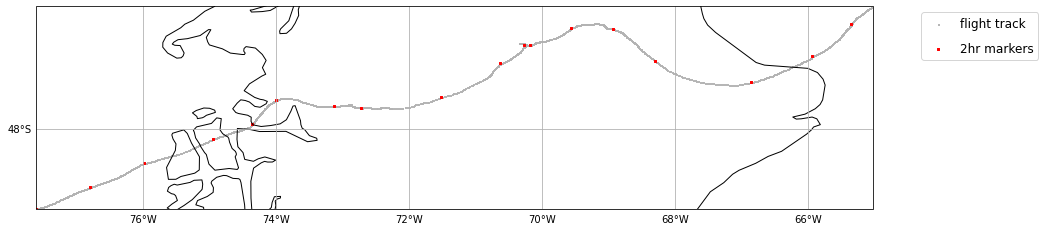

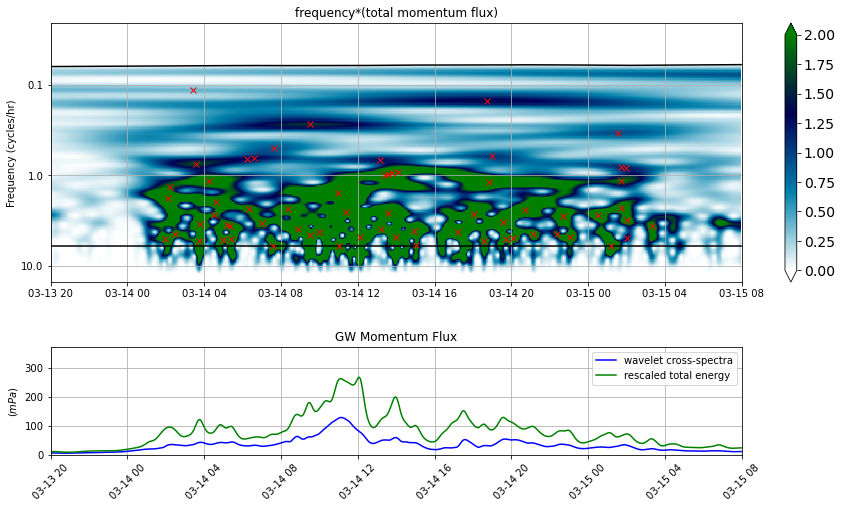

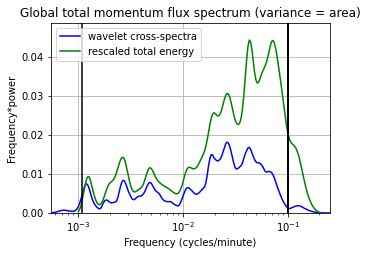

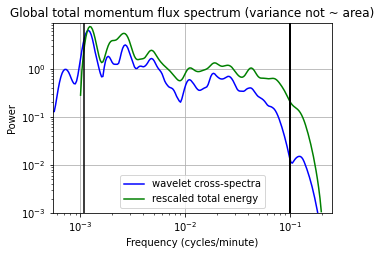

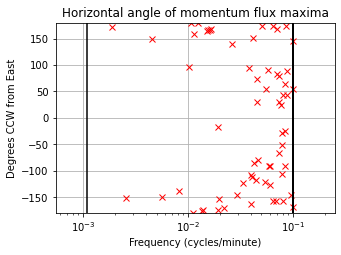

In [45]:
# Find maxima by testing whether a value is greater than the eight others in its vicinity:
# (x-axis: wavelet time; y_axis: wavelet period)
#
#   1    2    3
#   4  value  5
#   6    7    8
#
# Maxima near the edges are ignored, because they are outside the time or period ranges
# of interest.
field = wave_Etotal_scaled.copy()
field_total_flux = flux_total_Etotal.copy()
#field = rescaled_ReUVW_total.copy()
#field_total_flux = flux_total_ReUVW.copy()
maxima = np.zeros(shape=(nscales-2, N+2*N_pad-2))
# Grid cell #1: up one in scale, back one time step
temp = field[2:,:-2]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #2: up one in scale, no time shift
temp = field[2:,1:-1]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #3: up one in scale, forward one time step
temp = field[2:,2:]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #4: no scale shift, back one time step
temp = field[1:-1,:-2]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #5: no scale shift, forward one time step
temp = field[1:-1,2:]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #6: down one in scale, back one time step
temp = field[:-2,:-2]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #7: down one in scale, no time shift
temp = field[:-2,1:-1]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #8: down one in scale, forward one time step
temp = field[:-2,2:]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
del temp
# There is a maximum when maxima = 8:
maxima[maxima < 8] = 0
maxima[maxima == 8] = 1
# Change the shape of the maxima so that it has the same dimensions as wavelet
# output (nscales,N+2*N_pad)
temp = maxima.copy()
maxima = np.zeros(shape=(nscales, N+2*N_pad))
maxima[1:-1,1:-1] = temp
del temp
# Eliminate maxima in the zero padding regions
maxima[:,:N_pad] = 0
maxima[:,N+N_pad:] = 0
# Eliminate maxima outside the GW frequency range
maxima[np.isnan(coeff_factor) == True] = 0
# Eliminate maxima inside the COI
temp = np.zeros(N+2*N_pad)
temp[N_pad:N+N_pad] = coi
temp = np.tile(temp,(nscales,1))
maxima[period_tiled_padded > temp] = 0
del temp
# Eliminate maxima when the frequency-integrated GW momentum flux is below
# a threshold
temp = np.tile(1000*field_total_flux,(nscales,1))
maxima[temp < FLUX_THRESHOLD] = 0
del temp
# Eliminate maxima where the balloon isn't over the Andes
balloon_lon_padded = np.nan*np.ones(N+2*N_pad)
balloon_lon_padded[N_pad:N+N_pad] = balloon_lon
balloon_lon_padded[:N_pad] = balloon_lon[0]
balloon_lon_padded[N+N_pad:] = balloon_lon[-1]
temp_lat = np.tile(balloon_lat_padded,(nscales,1))
temp_lon = np.tile(balloon_lon_padded,(nscales,1))
temp = np.zeros(shape=(nscales,N+2*N_pad))
temp[temp_lat >= lat_box_min] = temp[temp_lat >= lat_box_min] + 1
temp[temp_lat <= lat_box_max] = temp[temp_lat <= lat_box_max] + 1
temp[temp_lon >= lon_box_min] = temp[temp_lon >= lon_box_min] + 1
temp[temp_lon <= lon_box_max] = temp[temp_lon <= lon_box_max] + 1
del temp_lat, temp_lon
maxima[temp < 4] = 0
del temp
n_maxima = int(np.sum(maxima))

# Compile the maxima into lists of periods and times
temp_time = np.tile(segment.time.iloc[0],(N+2*N_pad))
temp_time[N_pad:N+N_pad] = segment.time
temp_time[N+N_pad:] = segment.time.iloc[-1]
temp_time = np.tile(temp_time,(nscales,1))
maxima_time = temp_time[maxima == 1]
maxima_period = period_tiled_padded[maxima == 1]
maxima_period_ind = np.tile(np.arange(nscales),(N+2*N_pad,1)).swapaxes(0,1)
maxima_time_ind = np.tile(np.arange(N+2*N_pad), (nscales,1))
maxima_period_ind = maxima_period_ind[maxima == 1]
maxima_time_ind = maxima_time_ind[maxima == 1]
del temp_time

# Calculate the horizontal angle as the acrtangent of x- and y-fields averaged
# over a stencil around the maxima
x_field = np.real(std_u*crossspec_u_w/C_delta_uw)
y_field = np.real(std_v*crossspec_v_w/C_delta_vw)
maxima_theta_h = np.nan*np.ones(n_maxima)
for i in np.arange(n_maxima):
    
    # Retrive the x- and y-fields over the stencil
    period_ind = maxima_period_ind[i] - int((STENCIL_DIM-1)/2) + np.arange(STENCIL_DIM)
    time_ind = maxima_time_ind[i] - int((STENCIL_DIM-1)/2) + np.arange(STENCIL_DIM)
    x_field_temp = x_field[period_ind,time_ind]
    y_field_temp = y_field[period_ind,time_ind]
    field_temp = field[period_ind,time_ind]
    
    # Normalize to unit length and weight by the magnitude of the field
    temp = np.sqrt(x_field_temp**2 + y_field_temp**2)
    x_field_temp = x_field_temp*field_temp/temp
    y_field_temp = y_field_temp*field_temp/temp
    
    # Average their values, weighting them by 1/scale (could weight by frequency)
    # and take their arctangent
    weighting = np.tile(1/scale[period_ind],(STENCIL_DIM,1)).swapaxes(0,1)
    temp = x_field_temp/x_field_temp # in case there's NaNs
    x_field_temp = np.nansum(temp*x_field_temp*weighting)/np.nansum(temp*weighting)
    temp = y_field_temp/y_field_temp # in case there's NaNs
    y_field_temp = np.nansum(temp*y_field_temp*weighting)/np.nansum(temp*weighting)
    maxima_theta_h[i] = 180*np.arctan2(y_field_temp,x_field_temp)/np.pi

# Narrow down the time range, for plotting
time_start = pd.Timestamp('2014-03-13 20:00') # I-160 Andes crossing
time_stop = pd.Timestamp('2014-03-15 08:00') # I-160 Andes crossing
temp_ind = np.arange(N)
temp_ind = temp_ind[segment.time >= time_start]
ind_start = temp_ind[0] + N_pad
temp_ind = np.arange(N)
temp_ind = temp_ind[segment.time <= time_stop]
ind_stop = temp_ind[-1] + N_pad

# Select the maxima in this time window
maxima_period = maxima_period[maxima_time >= time_start]
maxima_theta_h = maxima_theta_h[maxima_time >= time_start]
maxima_time = maxima_time[maxima_time >= time_start]
maxima_period = maxima_period[maxima_time <= time_stop]
maxima_theta_h = maxima_theta_h[maxima_time <= time_stop]
maxima_time = maxima_time[maxima_time <= time_stop]

# Minimum and maximum period, for plotting
min_period = GW_PERIOD_MIN*np.ones(ind_stop - ind_start)
period_f = 2*Omega*np.sin(np.pi*balloon_lat_padded[ind_start:ind_stop]/180)
period_f = np.abs(2*np.pi/(60*period_f))
max_period = np.minimum(GW_PERIOD_MAX,period_f)

# Plot the segment
plt.figure(figsize=(15,15))
lat = balloon_lat_padded[ind_start:ind_stop].copy()
lon = balloon_lon_padded[ind_start:ind_stop].copy()
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([np.max([-180, np.min(lon)]), 
               np.min([180, np.max(lon)]), 
               np.max([-90, np.min(lat)]),
               np.min([90, np.max(lat)])], crs=ccrs.PlateCarree())
ax.coastlines(resolution='50m') # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,2))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,2))
plots = np.ndarray(shape=4,dtype='object')
plots[0] = plt.scatter(lon, lat, s=1, marker='s', color=[0.7,0.7,0.7], transform=ccrs.PlateCarree())
plots[1] = plt.scatter(lon[0:-1:60], lat[0:-1:60], s=5, marker='s', color='r', transform=ccrs.PlateCarree())
labels = np.ndarray(shape=2,dtype='object')
labels[0] = 'flight track'
labels[1] = '2hr markers'
leg = plt.legend(plots, labels, fontsize=12, bbox_to_anchor=(1.05, 1),
                 loc='upper left', labelspacing=1);
#plt.savefig('../plots/temp1.png', format='png', bbox_inches='tight');

# Plot the field and the maxima
fig = plt.figure(figsize=(12,6))
ax3 = plt.axes([0, 0.4, 1, 0.6])
temp = field[:,ind_start:ind_stop].copy()
freqs_temp = np.tile(60*frequency,(ind_stop-ind_start,1)).swapaxes(0,1)
fig3 = ax3.pcolormesh(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60*frequency),
                      freqs_temp*temp,vmin=0,vmax=2,cmap='ocean_r')
cbar = fig.colorbar(fig3,extend = 'both')
cbar.ax.tick_params(labelsize=14)
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/min_period),'k')
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/max_period),'k')
ax3.plot(maxima_time,np.log10(60/maxima_period),'rx')
ax3.grid()
ax3.set_title('frequency*(total momentum flux)')
ax3.set_ylabel('Frequency (cycles/hr)')
Yticks = 10**np.arange(np.ceil(np.log10(60*frequency.min())),np.ceil(np.log10(60*frequency.max())))
ax3.set_yticks(np.log10(Yticks))
ax3.set_yticklabels(Yticks)
#ax3.set_xticklabels([])
ax3.set_xlim(segment.time.iloc[ind_start-N_pad],segment.time.iloc[ind_stop-N_pad])
ax3.set_ylim(np.log10(60/4),np.log10(1/(2*24)));

# Plot the momentum flux time series
ax1 = plt.axes([0, 0, 0.8, 0.25])
ax1.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad], 1000*flux_total_ReUVW[ind_start:ind_stop], 'b')
ax1.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad], 1000*flux_total_Etotal[ind_start:ind_stop], 'g')
ax1.grid()
ax1.set_xlim(segment.time.iloc[ind_start-N_pad],segment.time.iloc[ind_stop-N_pad])
ax1.set_ylim(0,1.1*1000*np.nanmax(flux_total_Etotal))
ax1.tick_params('x',rotation=45)
ax1.set_title('GW Momentum Flux')
ax1.set_ylabel('$(mPa)$')
ax1.legend(['wavelet cross-spectra','rescaled total energy']);
#fig.savefig('../plots/temp2.png', format='png', bbox_inches='tight');

# Plot the global spectra
# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(5,3.5))
global_total_flux_temp = np.nanmean(rescaled_ReUVW_total[:,ind_start:ind_stop], axis=1)
global_Etotal_temp_scaled = np.nanmean(wave_Etotal_scaled[:,ind_start:ind_stop], axis=1)
plt.plot(frequency, frequency*global_total_flux_temp, 'b')
plt.plot(frequency, frequency*global_Etotal_temp_scaled, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.1*np.nanmax(frequency*global_Etotal_temp_scaled)],'k')
plt.plot([1/min_period, 1/min_period], [0, 1.1*np.nanmax(frequency*global_Etotal_temp_scaled)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(0,1.1*np.nanmax(frequency*global_Etotal_temp_scaled))
plt.xscale('log')
plt.title('Global total momentum flux spectrum (variance = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Frequency*power')
plt.legend(['wavelet cross-spectra','rescaled total energy']);
#plt.savefig('../plots/temp3.pdf', format='pdf', bbox_inches='tight');

# Plot the global spectra
# log(power) vs. log(frequency) (This method does not have variance ~ area)
plt.figure(figsize=(5,3.5))
global_total_flux_temp = np.nanmean(rescaled_ReUVW_total[:,ind_start:ind_stop], axis=1)
global_Etotal_temp_scaled = np.nanmean(wave_Etotal_scaled[:,ind_start:ind_stop], axis=1)
plt.plot(frequency, global_total_flux_temp, 'b')
plt.plot(frequency, global_Etotal_temp_scaled, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.2*np.nanmax(global_Etotal_temp_scaled)],'k')
plt.plot([1/min_period, 1/min_period], [0, 1.2*np.nanmax(global_Etotal_temp_scaled)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(1E-3,1.2*np.nanmax(global_Etotal_temp_scaled))
plt.xscale('log')
plt.yscale('log')
plt.title('Global total momentum flux spectrum (variance not ~ area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Power')
plt.legend(['wavelet cross-spectra','rescaled total energy']);
#plt.savefig('../plots/temp4.pdf', format='pdf', bbox_inches='tight');

# Plot the maxima horizontal angle
plt.figure(figsize=(5,3.5))
plt.plot(1/maxima_period, maxima_theta_h, 'rx')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [-180, 180],'k')
plt.plot([1/min_period, 1/min_period], [-180, 180],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(-180,180)
plt.xscale('log')
plt.title('Horizontal angle of momentum flux maxima')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Degrees CCW from East');
#plt.savefig('../plots/temp3.pdf', format='pdf', bbox_inches='tight');

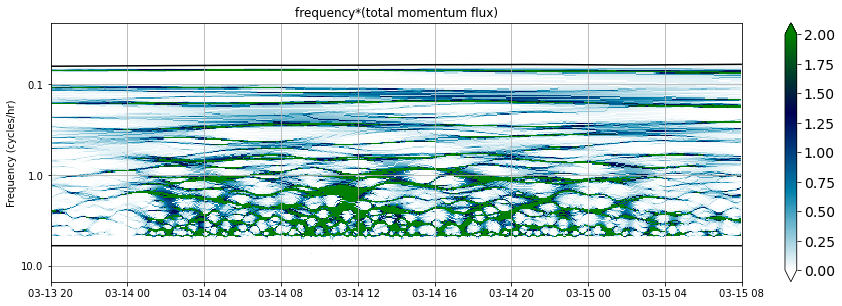

In [39]:
# Plot the field and the maxima
fig = plt.figure(figsize=(12,6))
ax3 = plt.axes([0, 0.4, 1, 0.6])
temp = field[:,ind_start:ind_stop].copy()
freqs_temp = np.tile(60*frequency,(ind_stop-ind_start,1)).swapaxes(0,1)
fig3 = ax3.pcolormesh(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60*frequency),
                      freqs_temp*temp,vmin=0,vmax=2,cmap='ocean_r')
cbar = fig.colorbar(fig3,extend = 'both')
cbar.ax.tick_params(labelsize=14)
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/min_period),'k')
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/max_period),'k')
ax3.grid()
ax3.set_title('frequency*(total momentum flux)')
ax3.set_ylabel('Frequency (cycles/hr)')
Yticks = 10**np.arange(np.ceil(np.log10(60*frequency.min())),np.ceil(np.log10(60*frequency.max())))
ax3.set_yticks(np.log10(Yticks))
ax3.set_yticklabels(Yticks)
#ax3.set_xticklabels([])
ax3.set_xlim(segment.time.iloc[ind_start-N_pad],segment.time.iloc[ind_stop-N_pad])
ax3.set_ylim(np.log10(60/4),np.log10(1/(2*24)));

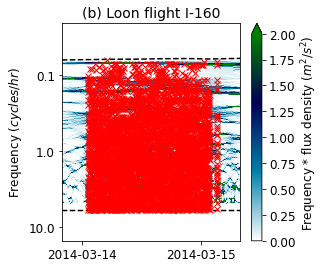

In [22]:
# Plot the field and the maxima
fig, ax3 = plt.subplots(figsize=(4,4))
temp = field[:,ind_start:ind_stop].copy()
freqs_temp = np.tile(60*frequency,(ind_stop-ind_start,1)).swapaxes(0,1)
fig3 = ax3.pcolormesh(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60*frequency),
                      freqs_temp*temp,vmin=0,vmax=2,cmap='ocean_r')
cbar = fig.colorbar(fig3,extend = 'max')
cbar.ax.tick_params(labelsize=12)
cbar.set_label('Frequency * flux density $(m^2/s^2)$', fontsize=12)
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/min_period),'--k')
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/max_period),'--k')
ax3.plot(maxima_time,np.log10(60/maxima_period),'rx')
ax3.set_title('(b) Loon flight I-160', fontsize=14)
ax3.set_ylabel('Frequency $(cycles/hr)$',fontsize=12)
myFmt = DateFormatter("%d")
ax3.xaxis.set_major_formatter(myFmt)
temp = segment.iloc[ind_start-N_pad:ind_stop-N_pad]
temp = temp['time'].dt.date
temp = temp.unique()
Xticks = temp
Yticks = 10**np.arange(np.ceil(np.log10(60*frequency.min())),np.ceil(np.log10(60*frequency.max())))
ax3.set_xticks(Xticks)
ax3.set_yticks(np.log10(Yticks))
ax3.set_xticklabels(Xticks, fontsize=12)
ax3.set_yticklabels(Yticks, fontsize=12)
ax3.set_xlim(segment.time.iloc[ind_start-N_pad],segment.time.iloc[ind_stop-N_pad])
ax3.set_ylim(np.log10(60/4),np.log10(1/(2*24)));
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');
#plt.savefig('../plots/temp2.png', format='png', bbox_inches='tight');

In [16]:
# Save the maxima period and theta_h
data = [maxima_period,
        maxima_theta_h]
#np.savez('Loon_maxima_flightI160_segment112_20mPaThresh_fluxEtot.npz', *data) 
np.savez('Loon_maxima_flightI160_segment112_50mPaThresh_fluxEtot.npz', *data) 

In [46]:
maxima_thetah_table = pd.DataFrame(columns=['time','period','theta_h'])
maxima_thetah_table.time = maxima_time
maxima_thetah_table.period = maxima_period
maxima_thetah_table.theta_h = maxima_theta_h
maxima_thetah_table = maxima_thetah_table.sort_values(by=['time']).reset_index(drop=True)
maxima_thetah_table

,time,period,theta_h
0,2014-03-14 01:58:00,11.986457,64.596162
1,2014-03-14 02:08:00,33.902819,-146.629542
2,2014-03-14 02:12:00,45.254834,-170.683209
3,2014-03-14 02:30:00,13.454343,29.483452
4,2014-03-14 03:26:00,527.002745,171.847975
...,...,...,...
68,2014-03-15 04:18:00,20.158737,173.307055
69,2014-03-15 04:44:00,10.079368,-158.272811
70,2014-03-15 05:26:00,73.942573,121.532627
71,2014-03-15 05:44:00,76.109255,115.784410


In [11]:
np.nanmean(1000*flux_total_ReUVW[ind_start:ind_stop])/np.nanmean(1000*flux_total_Etotal[ind_start:ind_stop])

0.4282326632223265